# Frame-Level EPV with Cervone Decomposition
## SkillCorner Open Data — Liga ACB 2025-26

**Architecture:** At each frame, predict the probability of the next terminal event
(shot, turnover, foul, end of possession), then compute EPV as the probability-weighted
sum of expected points for each outcome.

$$\text{EPV}_t = P(\text{shot}_t) \cdot E[\text{pts}|\text{shot}] + P(\text{TO}_t) \cdot 0 + P(\text{foul}_t) \cdot E[\text{pts}|\text{foul}] + P(\text{continue}_t) \cdot \text{EPV}_{t+1}$$

**Why this works with 10 games:** Instead of predicting the final possession outcome
from 150 frames away (too hard), we predict what happens in the NEXT few seconds.
That's a much simpler task — spatial configuration strongly predicts whether the
next action is a shot vs. a pass vs. a drive.

**Key references:**
- Cervone et al. (2014, 2016) — POINTWISE / Multiresolution EPV
- Alcorn & Nguyen (2021) — baller2vec multi-entity transformer
- Sicilia et al. (2019) — DeepHoops micro-action evaluation


## 1. Setup

In [1]:
import os, json, gzip, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, log_loss, classification_report
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')

DATA_DIR = os.path.expanduser("~/Desktop/opendata-basketball")


## 2. Load All 10 Games (Tracking + Events)

In [2]:
def load_game_full(game_id):
    game_dir = os.path.join(DATA_DIR, "data", "matches", str(game_id))
    gd_file = [f for f in os.listdir(game_dir) if f.endswith("game_data.json")][0]
    ev_file = [f for f in os.listdir(game_dir) if f.endswith("dynamic_events.json")][0]
    tk_file = [f for f in os.listdir(game_dir) if f.endswith("tracking_data.jsonl.gz")][0]
    
    with open(os.path.join(game_dir, gd_file)) as f: gd = json.load(f)
    with open(os.path.join(game_dir, ev_file)) as f: ev = json.load(f)
    
    tk_path = os.path.join(game_dir, tk_file)
    if os.path.getsize(tk_path) < 1000:
        print(f"  SKIP {game_id}: LFS pointer"); return None
    
    print(f"  Loading {game_id}...", end=" ")
    with gzip.open(tk_path, 'rt') as f:
        tracking = {json.loads(line)['frameIdx']: json.loads(line) for line in f}
    
    # Actually, reading twice is slow. Let's do it properly:
    tracking = {}
    with gzip.open(tk_path, 'rt') as f:
        for line in f:
            frame = json.loads(line)
            tracking[frame['frameIdx']] = frame
    
    players = {}
    for p in gd['homeTeam']['players']:
        players[p['playerId']] = {'name': f"{p['firstName'][0]}. {p['lastName']}", 'team': 'home'}
    for p in gd['awayTeam']['players']:
        players[p['playerId']] = {'name': f"{p['firstName'][0]}. {p['lastName']}", 'team': 'away'}
    
    print(f"{len(tracking)} frames")
    return {'game': gd, 'events': ev, 'tracking': tracking, 'players': players, 'game_id': game_id}

GAME_IDS = [114243, 114234, 114169, 114099, 114086, 178442, 179612, 184439, 188630, 191313]
games = {}
for gid in GAME_IDS:
    g = load_game_full(gid)
    if g: games[gid] = g
print(f"\nLoaded {len(games)} games")


  Loading 114243... 146870 frames
  Loading 114234... 158923 frames
  Loading 114169... 172257 frames
  Loading 114099... 147892 frames
  Loading 114086... 124796 frames
  Loading 178442... 162479 frames
  Loading 179612... 140856 frames
  Loading 184439... 154021 frames
  Loading 188630... 121793 frames
  Loading 191313... 143045 frames

Loaded 10 games


## 3. Label Every Frame with "Next Terminal Event"

For each frame in a possession, we label it with what happens next:
- `shot_made_2` / `shot_made_3` — made field goal
- `shot_miss_2` / `shot_miss_3` — missed field goal  
- `turnover` — possession ends with TO
- `foul` — shooting or non-shooting foul
- `end` — end of period, out of bounds, etc.
- `continue` — the possession is still developing

The point values for each terminal:
- shot_made_2 → 2, shot_made_3 → 3
- shot_miss → 0 (simplified; could add ORB probability)
- turnover → 0
- foul → ~1.4 (league average FT points per shooting foul)
- end → 0


In [3]:
# Compute league-average FT value from the 293-game aggregates
shots_agg = pd.read_csv(os.path.join(DATA_DIR, "data/aggregates/acb_shotsaggregates_20252026.csv"))

# Average points per shooting foul ~ FT rate * FT% * attempts
# We'll use 1.4 as a reasonable ACB estimate
FOUL_EV = 1.4

# Terminal event classes and their point values
TERMINALS = {
    'shot_made_2': 2.0,
    'shot_made_3': 3.0,
    'shot_miss_2': 0.0,
    'shot_miss_3': 0.0,
    'turnover': 0.0,
    'foul': FOUL_EV,
    'end': 0.0,
}
TERMINAL_CLASSES = list(TERMINALS.keys())
TERMINAL_VALUES = np.array([TERMINALS[c] for c in TERMINAL_CLASSES])

print("Terminal classes:", TERMINAL_CLASSES)
print("Point values:   ", TERMINAL_VALUES)


Terminal classes: ['shot_made_2', 'shot_made_3', 'shot_miss_2', 'shot_miss_3', 'turnover', 'foul', 'end']
Point values:    [2.  3.  0.  0.  0.  1.4 0. ]


In [4]:
def label_frames_for_game(game, subsample=5):
    """
    For each chance, label every subsampled frame with the terminal event type.
    
    Returns list of (state_vector, terminal_label, metadata) tuples.
    """
    ev = game['events']
    gd = game['game']
    tracking = game['tracking']
    home_id = gd['homeTeam']['teamId']
    
    samples = []
    
    for chance in ev['chances']:
        cid = chance['id']
        start_f = chance.get('startFrame')
        end_f = chance.get('endFrame')
        if start_f is None or end_f is None or end_f - start_f < 25:
            continue
        
        off_team = chance.get('offTeamId')
        home_is_off = (off_team == home_id)
        outcome = chance.get('outcome', '')
        
        # Determine terminal event
        terminal = 'end'
        
        # Check shots
        for s in ev['shots']:
            if s.get('chanceId') != cid: continue
            made = s.get('outcome', False)
            three = s.get('three', False)
            if made:
                terminal = 'shot_made_3' if three else 'shot_made_2'
            else:
                terminal = 'shot_miss_3' if three else 'shot_miss_2'
            break
        
        # Check turnovers
        if outcome == 'TO':
            terminal = 'turnover'
        elif outcome == 'FOU':
            terminal = 'foul'
        
        # Now label every frame
        for fi in range(start_f, end_f + 1, subsample):
            frame = tracking.get(fi)
            if frame is None: continue
            if len(frame.get('homePlayers', [])) != 5: continue
            if len(frame.get('awayPlayers', [])) != 5: continue
            
            state = extract_frame_state(frame, home_is_off)
            if state is None: continue
            
            # How far through the possession (0=start, 1=end)
            poss_frac = (fi - start_f) / max(end_f - start_f, 1)
            
            # Seconds remaining in possession
            poss_time_left = (end_f - fi) / 25.0
            
            # Add temporal features to state
            state_full = np.concatenate([state, [poss_frac, min(poss_time_left / 30.0, 1.0)]])
            
            samples.append({
                'state': state_full,
                'terminal': terminal,
                'chance_id': cid,
                'frame': fi,
                'game_id': game['game_id'],
                'poss_frac': poss_frac,
                'off_team': gd['homeTeam']['teamName'] if home_is_off else gd['awayTeam']['teamName'],
            })
    
    return samples


def extract_frame_state(frame, home_is_off):
    """
    Extract state vector from one tracking frame.
    
    32 features:
    - 5 offense players × 3 (x, y, speed) = 15
    - 5 defense players × 3 (x, y, speed) = 15
    - ball (x, y) = 2
    
    All normalized. Offense always attacks left (negative x).
    """
    hp = frame.get('homePlayers', [])
    ap = frame.get('awayPlayers', [])
    if len(hp) != 5 or len(ap) != 5: return None
    
    off_p = hp if home_is_off else ap
    def_p = ap if home_is_off else hp
    
    # Check if we need to flip (offense should be on negative x side)
    off_mean_x = np.mean([p['xyz'][0] for p in off_p])
    flip = off_mean_x > 0
    
    def coords(player):
        x, y = player['xyz'][0], player['xyz'][1]
        spd = player.get('speed', 0) or 0
        if flip: x, y = -x, -y
        return [x / 47.0, y / 25.0, min(spd / 30.0, 1.0)]
    
    # Sort by x (closest to hoop first)
    off_sorted = sorted(off_p, key=lambda p: p['xyz'][0] * (-1 if flip else 1))
    def_sorted = sorted(def_p, key=lambda p: p['xyz'][0] * (-1 if flip else 1))
    
    state = []
    for p in off_sorted: state.extend(coords(p))
    for p in def_sorted: state.extend(coords(p))
    
    # Ball
    ball = frame.get('ball')
    if ball and 'xyz' in ball:
        bx, by = ball['xyz'][0], ball['xyz'][1]
        if flip: bx, by = -bx, -by
        state.extend([bx / 47.0, by / 25.0])
    else:
        state.extend([0, 0])
    
    return np.array(state, dtype=np.float32)


In [5]:
# Extract labeled frames from all games
print("Labeling frames...")
all_samples = []
for gid, game in games.items():
    samples = label_frames_for_game(game, subsample=5)
    all_samples.extend(samples)
    # Count terminals
    terms = Counter(s['terminal'] for s in samples)
    print(f"  {gid}: {len(samples)} frames | {dict(terms)}")

print(f"\nTotal labeled frames: {len(all_samples)}")
print(f"Terminal distribution:")
term_counts = Counter(s['terminal'] for s in all_samples)
for t in TERMINAL_CLASSES:
    print(f"  {t:15s}: {term_counts.get(t,0):6d} ({100*term_counts.get(t,0)/len(all_samples):.1f}%)")


Labeling frames...
  114243: 11738 frames | {'foul': 1660, 'turnover': 1188, 'shot_miss_2': 3553, 'shot_miss_3': 2224, 'shot_made_3': 885, 'shot_made_2': 1825, 'end': 403}
  114234: 11457 frames | {'shot_made_2': 2199, 'shot_miss_3': 2350, 'shot_miss_2': 2037, 'turnover': 2193, 'foul': 1917, 'shot_made_3': 643, 'end': 118}
  114169: 11792 frames | {'end': 724, 'shot_made_2': 1718, 'foul': 1982, 'shot_miss_2': 3313, 'shot_miss_3': 2346, 'turnover': 765, 'shot_made_3': 944}
  114099: 11770 frames | {'shot_made_2': 1897, 'foul': 1559, 'turnover': 1012, 'shot_made_3': 1118, 'end': 418, 'shot_miss_3': 3026, 'shot_miss_2': 2740}
  114086: 11825 frames | {'foul': 1966, 'shot_miss_2': 2482, 'shot_made_2': 2033, 'shot_miss_3': 1824, 'turnover': 1747, 'end': 458, 'shot_made_3': 1315}
  178442: 14021 frames | {'shot_made_3': 1382, 'foul': 2055, 'shot_miss_3': 3057, 'turnover': 1384, 'shot_made_2': 3107, 'end': 466, 'shot_miss_2': 2570}
  179612: 12036 frames | {'turnover': 1503, 'foul': 2151, 'sh

## 4. Train Next-Event Classifier

A gradient boosting classifier predicts the terminal event type from the current frame state.
This gives us P(shot_made_2), P(shot_miss_3), P(turnover), etc. at every frame.


In [6]:
# Build feature matrix
X = np.array([s['state'] for s in all_samples])
y_labels = np.array([s['terminal'] for s in all_samples])

le = LabelEncoder()
le.fit(TERMINAL_CLASSES)
y = le.transform(y_labels)

print(f"X: {X.shape}, y: {y.shape}")
print(f"Features per frame: {X.shape[1]} (30 spatial + 2 temporal)")

X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
    X, y, all_samples, test_size=0.2, random_state=42)

print(f"Train: {len(X_train)}, Test: {len(X_test)}")


X: (120484, 34), y: (120484,)
Features per frame: 34 (30 spatial + 2 temporal)
Train: 96387, Test: 24097


In [7]:
# Train the next-event classifier
print("Training next-event classifier...")
clf = GradientBoostingClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    min_samples_leaf=30,
    random_state=42,
    verbose=1
)
clf.fit(X_train, y_train)
print("Done.")

# Evaluate
from sklearn.metrics import accuracy_score
y_pred = clf.predict(X_test)
y_pred_proba = clf.predict_proba(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Log loss: {log_loss(y_test, y_pred_proba):.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Training next-event classifier...
      Iter       Train Loss      OOB Improve   Remaining Time 
         1           1.8226           0.0083           41.24m
         2           1.8132           0.0015           41.37m
         3           1.8076           0.0110           41.24m
         4           1.7999           0.0057           41.39m
         5           1.7935           0.0059           41.55m
         6           1.7878           0.0071           41.62m
         7           1.7812           0.0027           41.95m
         8           1.7770           0.0108           41.94m
         9           1.7714           0.0025           41.88m
        10           1.7674           0.0094           41.79m
        20           1.7228           0.0047           41.40m
        30           1.6929           0.0070           40.12m
        40           1.6638          -0.0016           38.97m
        50           1.6394           0.0014           37.94m
        60           1.6182        

## 5. Compute EPV from Terminal Probabilities

$$\text{EPV}_t = \sum_k P(\text{terminal}_k | \text{state}_t) \times \text{points}_k$$


In [8]:
# Map classifier classes to point values
clf_classes = le.classes_
point_values = np.array([TERMINALS[c] for c in clf_classes])
print(f"Classes: {list(clf_classes)}")
print(f"Points:  {point_values}")

# Compute EPV for test set
epv_test = y_pred_proba @ point_values
y_true_pts = np.array([TERMINALS[le.inverse_transform([yi])[0]] for yi in y_test])

print(f"\nEPV Stats:")
print(f"  Mean predicted: {epv_test.mean():.3f}")
print(f"  Mean actual:    {y_true_pts.mean():.3f}")
print(f"  RMSE:           {np.sqrt(mean_squared_error(y_true_pts, epv_test)):.4f}")

# EPV at different points in possession
for lo, hi, label in [(0, 0.2, 'Early'), (0.2, 0.5, 'Mid'), (0.5, 0.8, 'Late'), (0.8, 1.0, 'Terminal')]:
    mask = np.array([lo <= m['poss_frac'] < hi for m in meta_test])
    if mask.sum() > 0:
        rmse = np.sqrt(mean_squared_error(y_true_pts[mask], epv_test[mask]))
        print(f"  {label:10s} ({mask.sum():5d} frames): RMSE={rmse:.4f}, mean EPV={epv_test[mask].mean():.3f}")


Classes: [np.str_('end'), np.str_('foul'), np.str_('shot_made_2'), np.str_('shot_made_3'), np.str_('shot_miss_2'), np.str_('shot_miss_3'), np.str_('turnover')]
Points:  [0.  1.4 2.  3.  0.  0.  0. ]

EPV Stats:
  Mean predicted: 0.889
  Mean actual:    0.888
  RMSE:           0.9459
  Early      ( 4621 frames): RMSE=0.9472, mean EPV=0.873
  Mid        ( 7121 frames): RMSE=0.9399, mean EPV=0.884
  Late       ( 7322 frames): RMSE=0.9675, mean EPV=0.897
  Terminal   ( 4934 frames): RMSE=0.9226, mean EPV=0.898


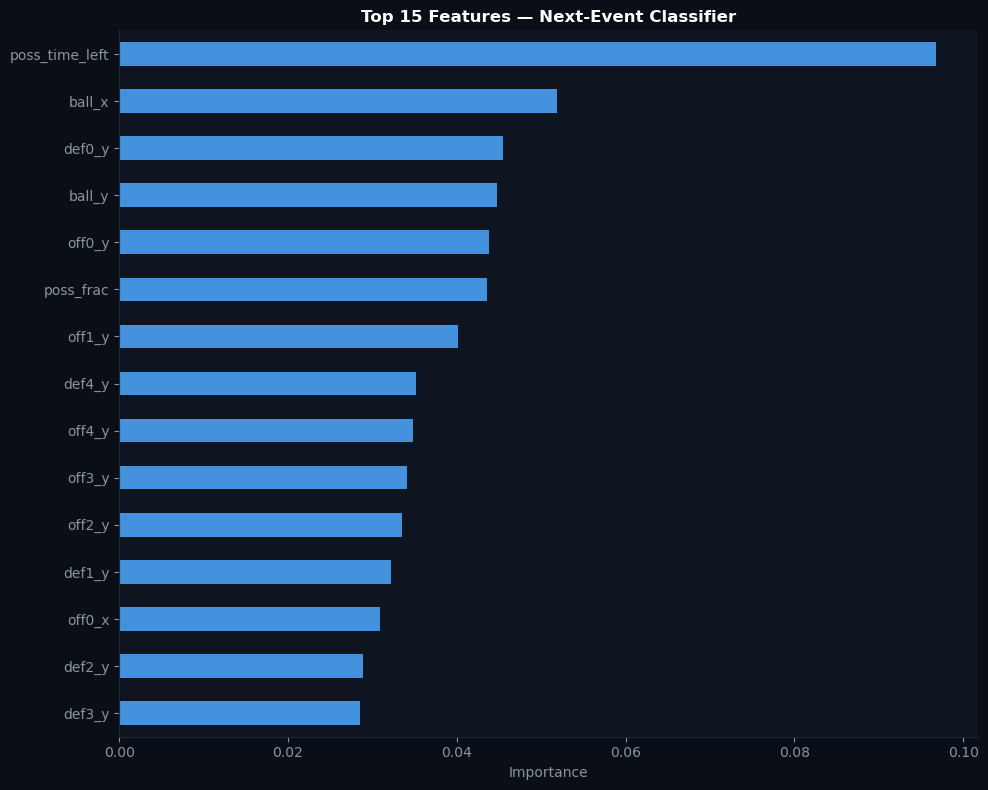

In [9]:
# Feature importance
feat_names = (
    [f'off{i}_{c}' for i in range(5) for c in ['x','y','spd']] +
    [f'def{i}_{c}' for i in range(5) for c in ['x','y','spd']] +
    ['ball_x','ball_y','poss_frac','poss_time_left']
)

importances = pd.Series(clf.feature_importances_, index=feat_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10,8), facecolor='#0a0e16')
ax.set_facecolor('#0e1420')
importances.head(15).plot.barh(ax=ax, color='#4ea8ff', alpha=0.85)
ax.invert_yaxis()
ax.set_xlabel('Importance', color='#8b949e')
ax.set_title('Top 15 Features — Next-Event Classifier', color='white', fontweight='bold')
ax.tick_params(colors='#8b949e')
ax.spines['bottom'].set_color('#1e2a36'); ax.spines['left'].set_color('#1e2a36')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('epv_v3_feature_importance.png', dpi=150, facecolor='#0a0e16', bbox_inches='tight')
plt.show()


## 6. EPV Curves for Individual Possessions

In [10]:
def plot_epv_curve_v3(clf, game, chance_id, point_values, le, subsample=5):
    """Plot frame-level EPV curve for a single possession."""
    ev = game['events']
    gd = game['game']
    tracking = game['tracking']
    home_id = gd['homeTeam']['teamId']
    
    chance = None
    for ch in ev['chances']:
        if ch['id'] == chance_id:
            chance = ch; break
    if chance is None: return None
    
    off_team = chance.get('offTeamId')
    home_is_off = (off_team == home_id)
    off_name = gd['homeTeam']['teamName'] if home_is_off else gd['awayTeam']['teamName']
    start_f = chance['startFrame']
    end_f = chance['endFrame']
    
    # Determine actual outcome
    terminal = 'end'
    target_pts = 0
    for s in ev['shots']:
        if s.get('chanceId') != chance_id: continue
        made = s.get('outcome', False)
        three = s.get('three', False)
        if made: target_pts = 3 if three else 2
        break
    if chance.get('outcome') == 'TO': terminal = 'turnover'
    
    # Collect events for annotation
    event_markers = []
    for atype, elist in [('pick', ev['picks']), ('drive', ev['drives']),
                          ('shot', ev['shots']), ('pass', ev['passes']),
                          ('turnover', ev['turnovers']), ('foul', ev['fouls']),
                          ('isolation', ev['isolations']), ('closeout', ev['closeouts'])]:
        for e in elist:
            if e.get('chanceId') != chance_id: continue
            frame = e.get('frame') or e.get('startFrame') or 0
            event_markers.append((frame, atype, e))
    event_markers.sort(key=lambda x: x[0])
    
    # Compute EPV at each frame
    frames = []
    epvs = []
    probs_list = []
    
    for fi in range(start_f, end_f + 1, subsample):
        frame = tracking.get(fi)
        if frame is None or len(frame.get('homePlayers',[])) != 5: continue
        state = extract_frame_state(frame, home_is_off)
        if state is None: continue
        poss_frac = (fi - start_f) / max(end_f - start_f, 1)
        poss_time_left = (end_f - fi) / 25.0
        state_full = np.concatenate([state, [poss_frac, min(poss_time_left/30.0, 1.0)]])
        
        proba = clf.predict_proba(state_full.reshape(1, -1))[0]
        epv = proba @ point_values
        
        frames.append(fi)
        epvs.append(epv)
        probs_list.append(proba)
    
    if len(frames) < 3: return None
    
    epvs = np.array(epvs)
    time_sec = (np.array(frames) - frames[0]) / 25.0
    
    # Plot
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), facecolor='#0a0e16',
                              gridspec_kw={'height_ratios': [3, 1]})
    
    # Top: EPV curve
    ax = axes[0]
    ax.set_facecolor('#0e1420')
    ax.plot(time_sec, epvs, color='#4ea8ff', linewidth=2.5, zorder=3)
    ax.fill_between(time_sec, 0, epvs, color='#4ea8ff', alpha=0.08)
    ax.axhline(y=target_pts, color='#34d399' if target_pts>0 else '#f87171',
               linestyle='--', alpha=0.4)
    ax.text(time_sec[-1], target_pts+0.05, f'{target_pts}pts',
            color='#34d399' if target_pts>0 else '#f87171', fontsize=10)
    
    # Annotate events
    action_colors = {'pick':'#fbbf24','drive':'#a78bfa','shot':'#34d399',
                     'pass':'#555555','turnover':'#f87171','foul':'#f87171',
                     'isolation':'#f472b6','closeout':'#f59e42'}
    for eframe, etype, edata in event_markers:
        t = (eframe - frames[0]) / 25.0
        if t < 0 or t > time_sec[-1]: continue
        # Find closest EPV
        idx = np.argmin(np.abs(time_sec - t))
        epv_at = epvs[idx]
        col = action_colors.get(etype, '#8b949e')
        ax.axvline(x=t, color=col, alpha=0.2, linewidth=1)
        ax.scatter(t, epv_at, color=col, s=50, zorder=5, edgecolors='white', linewidth=0.5)
        label = etype
        if etype == 'pick':
            cov = edata.get('bhrDefType', '')
            if cov: label = f'pick\n({cov})'
        ax.text(t, epv_at + 0.1, label, ha='center', va='bottom', fontsize=7, color=col)
    
    ax.set_ylabel('Expected Points', color='#8b949e')
    ax.set_title(f"EPV — {off_name} | Q{chance['period']} | Outcome: {target_pts}pts ({chance.get('outcome','')})",
                 color='white', fontsize=13, fontweight='bold')
    ax.set_ylim(-0.1, 3.2)
    ax.tick_params(colors='#8b949e')
    ax.spines['bottom'].set_color('#1e2a36'); ax.spines['left'].set_color('#1e2a36')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.grid(axis='y', color='#1e2a36', alpha=0.3)
    
    # Bottom: terminal probability breakdown
    ax2 = axes[1]
    ax2.set_facecolor('#0e1420')
    probs_arr = np.array(probs_list)
    prob_colors = {'shot_made_2':'#34d399','shot_made_3':'#22c55e','shot_miss_2':'#f87171',
                   'shot_miss_3':'#ef4444','turnover':'#8b949e','foul':'#fbbf24','end':'#555555'}
    for ci, cname in enumerate(clf.classes_):
        if cname in ['end']: continue
        col = prob_colors.get(cname, '#888')
        ax2.plot(time_sec, probs_arr[:, ci], color=col, linewidth=1.2, alpha=0.8, label=cname)
    ax2.legend(fontsize=7, loc='upper right', ncol=3, framealpha=0.3,
               labelcolor='#8b949e', edgecolor='#1e2a36')
    ax2.set_xlabel('Time (seconds)', color='#8b949e')
    ax2.set_ylabel('P(terminal)', color='#8b949e')
    ax2.set_ylim(0, 1)
    ax2.tick_params(colors='#8b949e')
    ax2.spines['bottom'].set_color('#1e2a36'); ax2.spines['left'].set_color('#1e2a36')
    ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
    
    plt.tight_layout()
    return fig


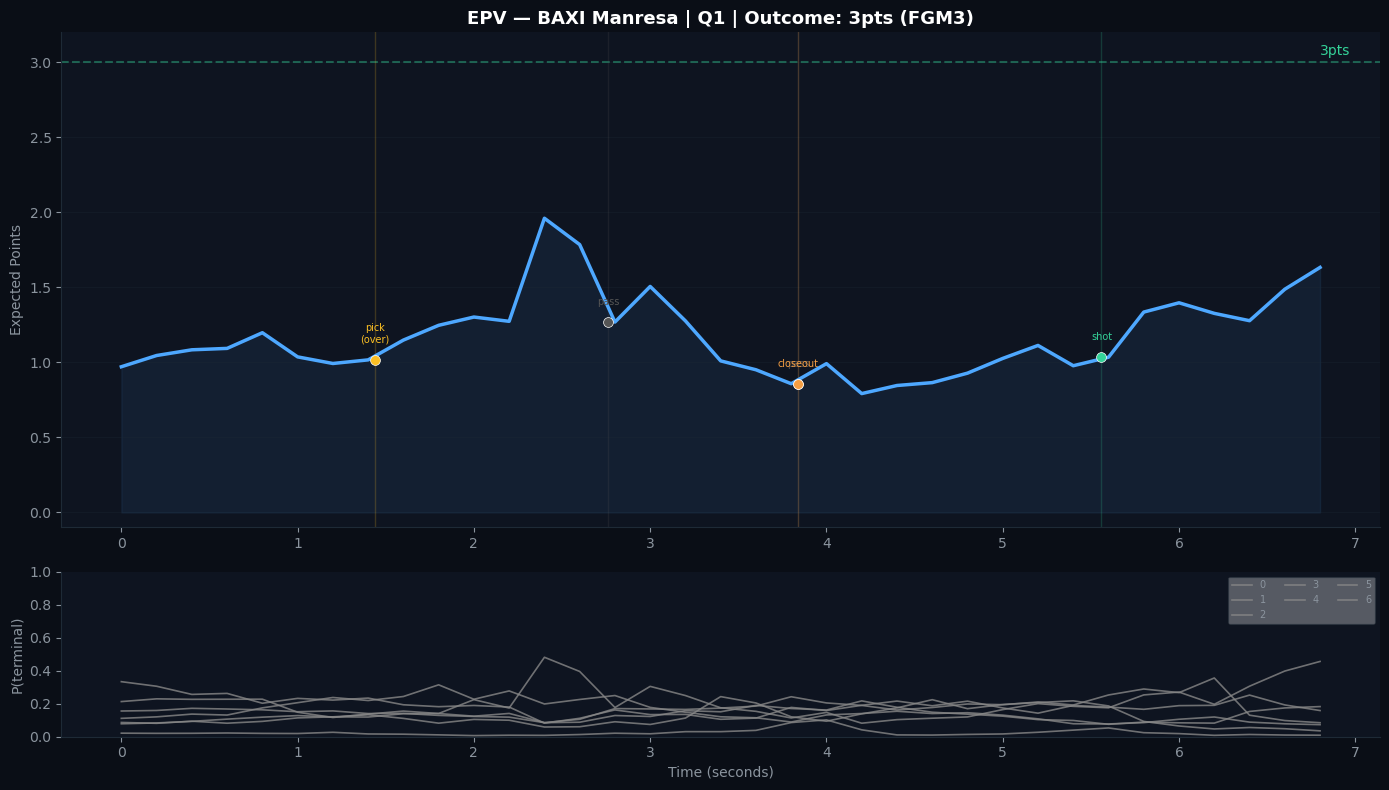

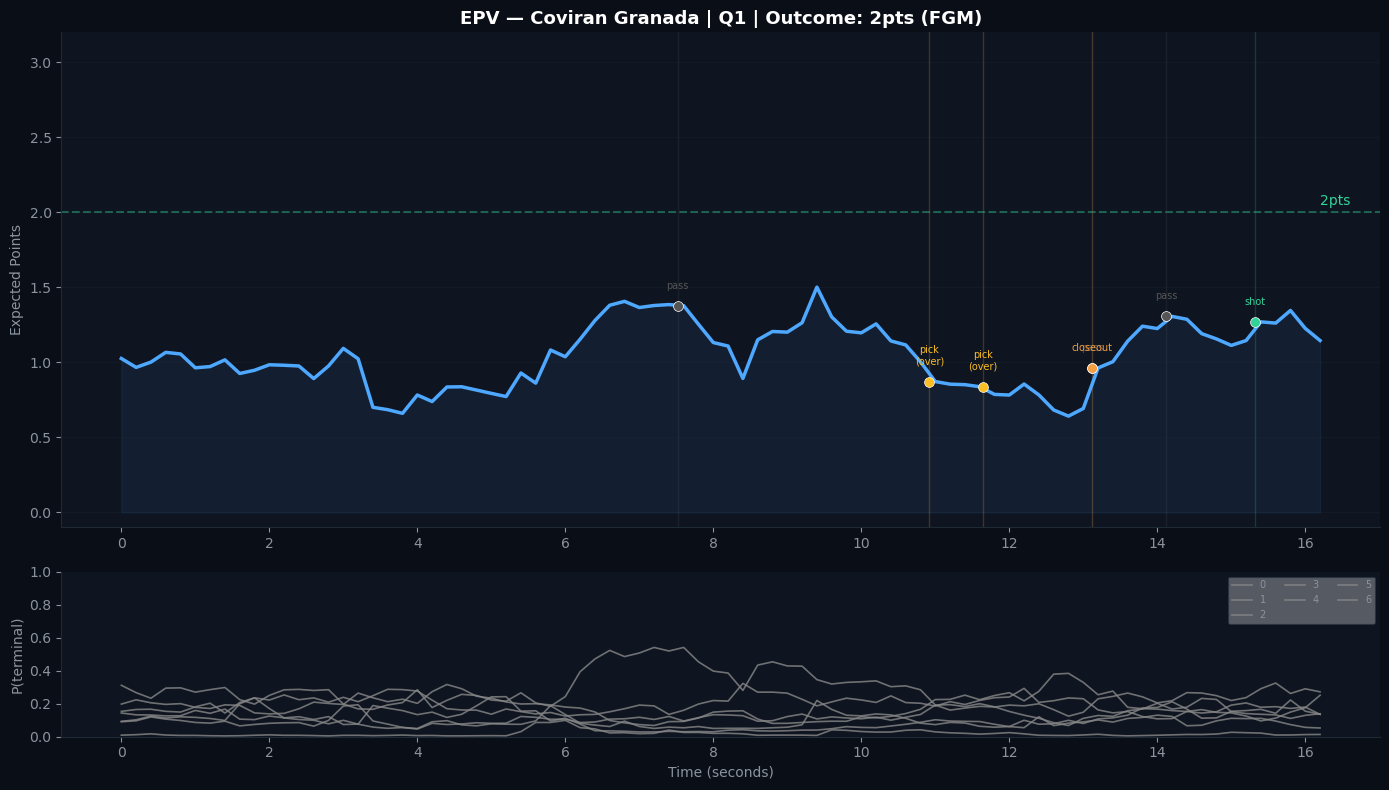

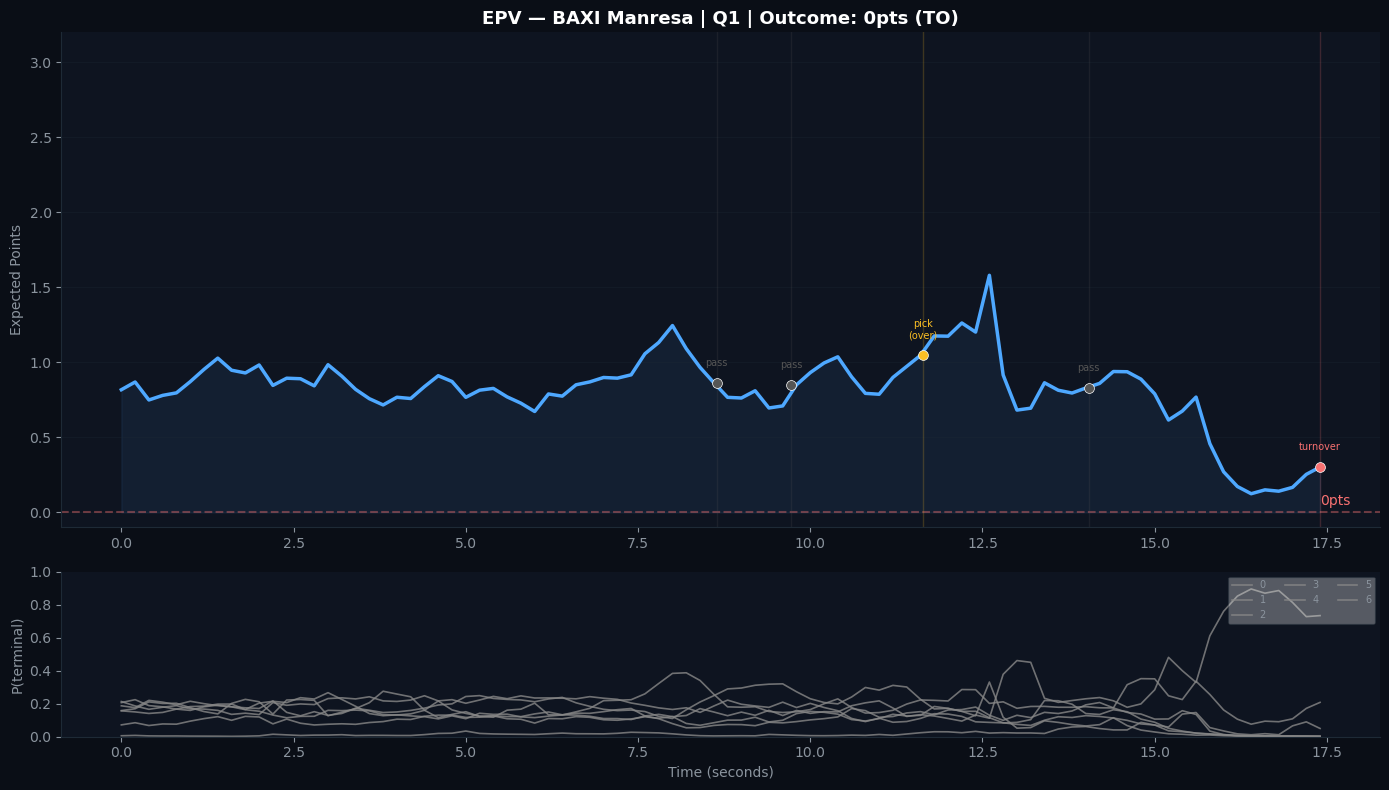

In [11]:
# Find interesting possessions and plot
# Made 3
for gid, game in games.items():
    for ch in game['events']['chances']:
        if ch['outcome'] == 'FGM3':
            for s in game['events']['shots']:
                if s.get('chanceId') == ch['id'] and s.get('outcome'):
                    fig = plot_epv_curve_v3(clf, game, ch['id'], point_values, le)
                    if fig:
                        fig.savefig('epv_v3_curve_3pt.png', dpi=150, facecolor='#0a0e16', bbox_inches='tight')
                        plt.show()
                    break
            else: continue
            break
    else: continue
    break

# Made 2 with picks
for gid, game in games.items():
    pick_chances = set(p['chanceId'] for p in game['events']['picks'])
    for ch in game['events']['chances']:
        if ch['outcome'] == 'FGM' and ch['id'] in pick_chances:
            fig = plot_epv_curve_v3(clf, game, ch['id'], point_values, le)
            if fig:
                fig.savefig('epv_v3_curve_2pt_pnr.png', dpi=150, facecolor='#0a0e16', bbox_inches='tight')
                plt.show()
            break
    else: continue
    break

# Turnover
for gid, game in games.items():
    for ch in game['events']['chances']:
        if ch['outcome'] == 'TO' and (ch.get('endFrame',0) - ch.get('startFrame',0)) > 100:
            fig = plot_epv_curve_v3(clf, game, ch['id'], point_values, le)
            if fig:
                fig.savefig('epv_v3_curve_turnover.png', dpi=150, facecolor='#0a0e16', bbox_inches='tight')
                plt.show()
            break
    else: continue
    break


## 7. Validate: EPV at Shot Frame vs Shot Quality

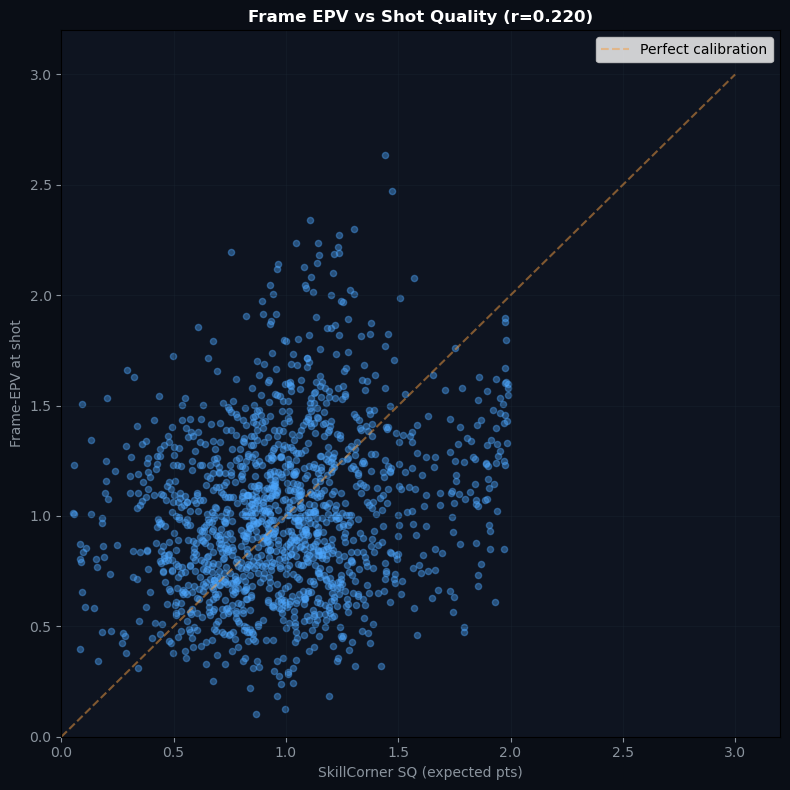

Correlation: 0.220
RMSE: 0.4750
N shots: 1433


In [15]:
shot_epvs = []; shot_sqs = []

for gid, game in games.items():
    ev = game['events']; gd = game['game']; tracking = game['tracking']
    home_id = gd['homeTeam']['teamId']
    
    for s in ev['shots']:
        cid = s.get('chanceId')
        sq = s.get('shotQuality')
        if sq is None or sq == 0: continue
        
        # Find the chance
        chance = None
        for ch in ev['chances']:
            if ch['id'] == cid: chance = ch; break
        if chance is None: continue
        
        off_team = chance.get('offTeamId')
        home_is_off = (off_team == home_id)
        
        # Get the frame nearest to the shot
        shot_frame = s.get('startFrame') or s.get('frame')
        if shot_frame is None: continue
        
        frame = tracking.get(shot_frame)
        if frame is None or len(frame.get('homePlayers',[])) != 5: continue
        
        state = extract_frame_state(frame, home_is_off)
        if state is None: continue
        
        start_f = chance.get('startFrame', shot_frame)
        end_f = chance.get('endFrame', shot_frame)
        poss_frac = (shot_frame - start_f) / max(end_f - start_f, 1)
        poss_time_left = (end_f - shot_frame) / 25.0
        state_full = np.concatenate([state, [poss_frac, min(poss_time_left/30.0, 1.0)]])
        
        proba = clf.predict_proba(state_full.reshape(1,-1))[0]
        epv = proba @ point_values
        
        three = s.get('three', False)
        sq_pts = (sq / 100.0) * (3 if three else 2)
        
        shot_epvs.append(epv)
        shot_sqs.append(sq_pts)

shot_epvs = np.array(shot_epvs); shot_sqs = np.array(shot_sqs)
corr = np.corrcoef(shot_sqs, shot_epvs)[0,1]

fig, ax = plt.subplots(figsize=(8,8), facecolor='#0a0e16')
ax.set_facecolor('#0e1420')
ax.scatter(shot_sqs, shot_epvs, alpha=0.4, s=20, color='#4ea8ff')
ax.plot([0,3],[0,3],'--',color='#f59e42',alpha=0.5,label='Perfect calibration')
ax.set_xlabel('SkillCorner SQ (expected pts)', color='#8b949e')
ax.set_ylabel('Frame-EPV at shot', color='#8b949e')
ax.set_title(f'Frame EPV vs Shot Quality (r={corr:.3f})', color='white', fontweight='bold')
ax.tick_params(colors='#8b949e'); ax.legend()
ax.grid(color='#1e2a36',alpha=0.3); ax.set_xlim(0,3.2); ax.set_ylim(0,3.2)
plt.tight_layout()
plt.savefig('epv_v3_vs_sq.png', dpi=150, facecolor='#0a0e16', bbox_inches='tight')
plt.show()
print(f"Correlation: {corr:.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(shot_sqs, shot_epvs)):.4f}")
print(f"N shots: {len(shot_epvs)}")


## 8. EPV-Added by Action Type

In [13]:
action_deltas = defaultdict(list)
coverage_deltas = defaultdict(list)

for gid, game in games.items():
    ev = game['events']; gd = game['game']; tracking = game['tracking']
    home_id = gd['homeTeam']['teamId']
    
    for chance in ev['chances']:
        cid = chance['id']
        start_f = chance.get('startFrame')
        end_f = chance.get('endFrame')
        if start_f is None or end_f is None: continue
        
        off_team = chance.get('offTeamId')
        home_is_off = (off_team == home_id)
        
        # Get events in this chance
        chance_events = []
        for atype, elist in [('pick',ev['picks']),('drive',ev['drives']),
                              ('shot',ev['shots']),('isolation',ev['isolations']),
                              ('closeout',ev['closeouts']),('turnover',ev['turnovers'])]:
            for e in elist:
                if e.get('chanceId') != cid: continue
                ef = e.get('frame') or e.get('startFrame') or 0
                chance_events.append((ef, atype, e))
        chance_events.sort(key=lambda x: x[0])
        
        # Compute EPV before and after each event
        for eframe, etype, edata in chance_events:
            before_f = max(start_f, eframe - 10)
            after_f = min(end_f, eframe + 10)
            
            epvs = []
            for fi in [before_f, after_f]:
                frame = tracking.get(fi)
                if frame is None or len(frame.get('homePlayers',[])) != 5:
                    epvs.append(None); continue
                state = extract_frame_state(frame, home_is_off)
                if state is None: epvs.append(None); continue
                pf = (fi - start_f) / max(end_f - start_f, 1)
                ptl = (end_f - fi) / 25.0
                sf = np.concatenate([state, [pf, min(ptl/30.0,1.0)]])
                proba = clf.predict_proba(sf.reshape(1,-1))[0]
                epvs.append(proba @ point_values)
            
            if epvs[0] is not None and epvs[1] is not None:
                delta = epvs[1] - epvs[0]
                action_deltas[etype].append(delta)
                
                if etype == 'pick':
                    cov = edata.get('bhrDefType', 'unknown')
                    if cov: coverage_deltas[cov].append(delta)

print("=== EPV Change by Action Type (Frame-Level) ===\n")
rows = []
for atype, deltas in action_deltas.items():
    if len(deltas) >= 10:
        rows.append({'action': atype, 'mean_delta': np.mean(deltas),
                     'count': len(deltas), 'positive_pct': 100*np.mean([d>0 for d in deltas])})
adf = pd.DataFrame(rows).sort_values('mean_delta', ascending=False)
print(adf.to_string(index=False))

print("\n=== EPV Change by Pick Coverage (Frame-Level) ===\n")
for cov in ['over','under','switch','ice','blitz']:
    if cov in coverage_deltas and len(coverage_deltas[cov]) >= 3:
        d = coverage_deltas[cov]
        print(f"  {cov:8s}: mean={np.mean(d):+.4f}, n={len(d)}, positive={100*np.mean([x>0 for x in d]):.0f}%")


=== EPV Change by Action Type (Frame-Level) ===

   action  mean_delta  count  positive_pct
     shot    0.022922   1458     54.252401
    drive    0.022643    659     55.993930
 turnover    0.021308    246     53.658537
     pick    0.018562   1520     55.526316
 closeout    0.009922    600     50.000000
isolation    0.009730    180     56.111111

=== EPV Change by Pick Coverage (Frame-Level) ===

  over    : mean=+0.0287, n=1004, positive=58%
  under   : mean=-0.0065, n=280, positive=49%
  switch  : mean=+0.0028, n=218, positive=54%
  ice     : mean=+0.0140, n=14, positive=57%
  blitz   : mean=+0.1032, n=4, positive=100%


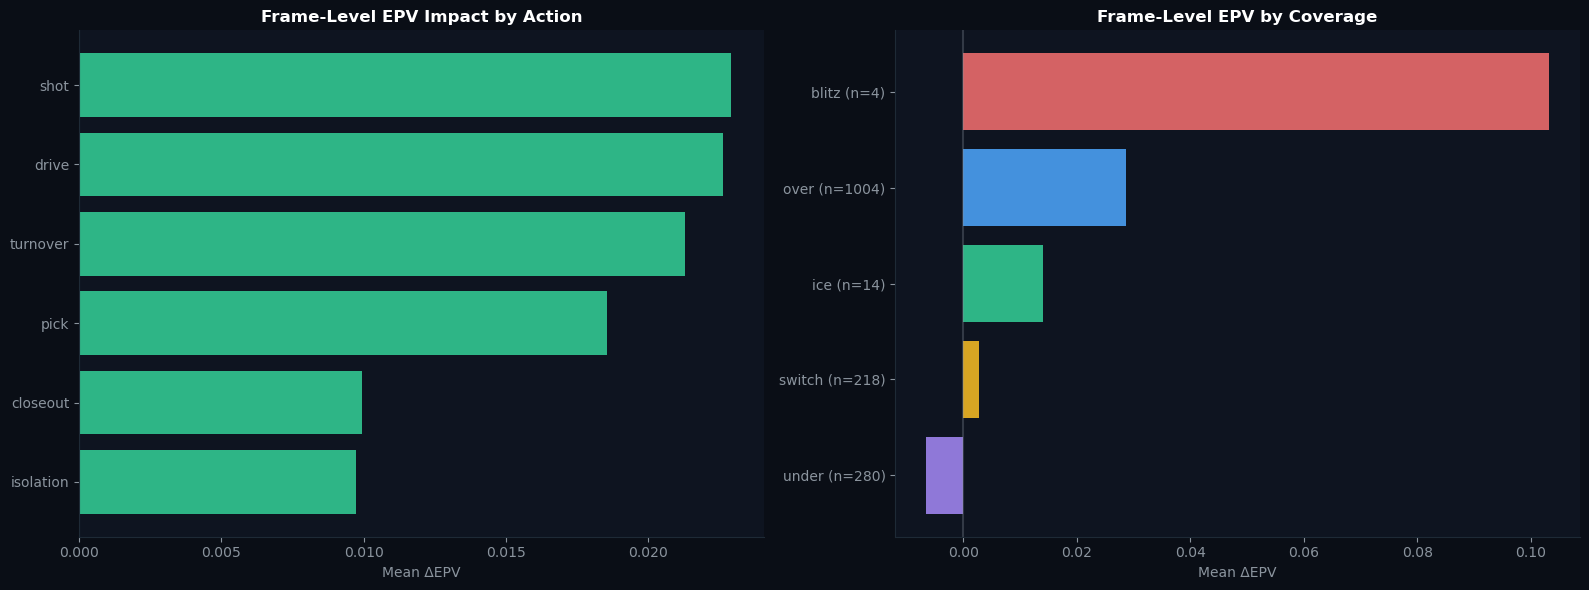

In [14]:
# Visualize
fig, axes = plt.subplots(1,2,figsize=(16,6),facecolor='#0a0e16')
ax = axes[0]; ax.set_facecolor('#0e1420')
colors = ['#34d399' if v>0 else '#f87171' for v in adf['mean_delta']]
ax.barh(range(len(adf)),adf['mean_delta'],color=colors,alpha=0.85)
ax.set_yticks(range(len(adf))); ax.set_yticklabels(adf['action'],color='#8b949e')
ax.invert_yaxis(); ax.set_xlabel('Mean ΔEPV',color='#8b949e')
ax.set_title('Frame-Level EPV Impact by Action',color='white',fontweight='bold')
ax.axvline(x=0,color='#8b949e',alpha=0.3)
ax.tick_params(colors='#8b949e')
ax.spines['bottom'].set_color('#1e2a36');ax.spines['left'].set_color('#1e2a36')
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)

ax=axes[1];ax.set_facecolor('#0e1420')
cc = {'over':'#4ea8ff','under':'#a78bfa','switch':'#fbbf24','ice':'#34d399','blitz':'#f87171'}
cd = [(c,np.mean(d),len(d)) for c,d in coverage_deltas.items() if len(d)>=3]
cd.sort(key=lambda x:x[1],reverse=True)
if cd:
    cn,cm,ccn=zip(*cd)
    ax.barh(range(len(cn)),cm,color=[cc.get(c,'#888') for c in cn],alpha=0.85)
    ax.set_yticks(range(len(cn)))
    ax.set_yticklabels([f"{c} (n={n})" for c,n in zip(cn,ccn)],color='#8b949e')
    ax.invert_yaxis();ax.axvline(x=0,color='#8b949e',alpha=0.3)
ax.set_xlabel('Mean ΔEPV',color='#8b949e')
ax.set_title('Frame-Level EPV by Coverage',color='white',fontweight='bold')
ax.tick_params(colors='#8b949e')
ax.spines['bottom'].set_color('#1e2a36');ax.spines['left'].set_color('#1e2a36')
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('epv_v3_action_analysis.png',dpi=150,facecolor='#0a0e16',bbox_inches='tight')
plt.show()


## 9. Next Steps
- **baller2vec architecture**: Replace GBM with multi-entity transformer for the next-event classifier
- **Richer terminal model**: Add offensive rebound probability to shot_miss terminals
- **Player embeddings**: Capture individual shooting/playmaking tendencies
- **Shapley attribution**: Decompose EPV-Added into individual player contributions (per MIT Sloan TD paper)
- **Overlay on court animation**: Map EPV values onto the animated play viewer
